# Credit Approval Classification

**Mehmet Mikail Karaman**

An English presentation of a tabular machine learning experiment on the UCI Credit Approval dataset. Saved metrics are retained from the supplied Final.ipynb; models were not retrained for this publication.

The workflow compares classifiers, explores Gradient Boosting hyperparameters, and inspects model generalization. See README for preprocessing and evaluation limitations.


## Imports and dependencies

Import the data-processing, visualization, classification, and evaluation tools.


In [3]:
import numpy as np
import pandas as pd
from ydata_profiling import ProfileReport
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")




## Load the UCI dataset

Fetch dataset 27 and name the 15 anonymized features A1–A15.


In [7]:
def load_data():
    data = fetch_ucirepo(id=27)
    X = data.data.features
    y = data.data.targets

    X.columns = [f"A{i}" for i in range(1, 16)]

    df = pd.concat([X, y], axis=1)


    df.rename(columns={df.columns[-1]: "class"}, inplace=True)

    return df

## Preprocess mixed-type features

Replace missing-value markers, impute values, encode categories, and map +/− labels to 1/0. This original workflow fits imputation before the split; see the evaluation caveats.


In [10]:
def preprocess_data(df):
    print("Starting preprocessing...")


    y = df["class"].copy()
    X = df.drop("class", axis=1).copy()


    X = X.replace("?", np.nan)


    for col in X.columns:
        if X[col].dtype == "object":
            X[col] = X[col].fillna(X[col].mode()[0])
        else:
            X[col] = X[col].fillna(X[col].median())

    print("Shape after missing-value imputation:", X.shape)


    X = pd.get_dummies(X, drop_first=True)

    print("Shape after encoding:", X.shape)


    y = y.astype(str).str.strip()
    y = y.map({"+": 1, "-": 0})


    y = y.loc[X.index]


    df_final = pd.concat([X, y.rename("class")], axis=1)

    return df_final

## Stratified train/test split

Use an 80/20 split with random_state=42 and preserve class proportions.


In [11]:
from sklearn.model_selection import train_test_split
def split_data(df):
    X = df.drop("class", axis=1)
    y = df["class"]
    print("\nTarget distribution:")
    print(y.value_counts())
    return train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

## Prepare the experiment data

The saved run contains 552 training records and 138 test records, with 37 encoded features.


In [13]:
df = load_data()
df = preprocess_data(df)

X_train, X_test, y_train, y_test = split_data(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Starting preprocessing...
Shape after missing-value imputation: (690, 15)
Shape after encoding: (690, 37)

Target distribution:
class
0    383
1    307
Name: count, dtype: int64
Train shape: (552, 37)
Test shape: (138, 37)


## Scale the features

Fit StandardScaler on the training subset and transform the test subset.


In [14]:
from sklearn.preprocessing import StandardScaler

print("\n--- FEATURE SCALING ---")
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


--- FEATURE SCALING ---


## Define five baseline classifiers

Compare Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and an SVM with probability estimates.


In [16]:
X_train = X_train_scaled
X_test = X_test_scaled

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "SVM": SVC(probability=True)
}

In [17]:
print("Training target distribution:")
print(pd.Series(y_train).value_counts())

Training target distribution:
class
0    306
1    246
Name: count, dtype: int64


In [18]:
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
Gradient Boosting trained
SVM trained


## Tune Gradient Boosting

Search 16 parameter combinations with five-fold cross-validation using F1 as the selection metric.


In [28]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

print("\n==============================")
print("GRID SEARCH (Gradient Boosting)")
print("==============================")

param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.01, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0]
}

grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)

best_model = grid.best_estimator_


GRID SEARCH (Gradient Boosting)
Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}


## Inspect cross-validation scores

Evaluate the selected model using five folds. These folds reuse the tuning data and do not form an independent nested evaluation.


In [29]:
print("\n==============================")
print("CROSS VALIDATION (Best Model)")
print("==============================")

cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5, scoring="f1")

print("CV Scores:", cv_scores)
print("CV Mean F1 Score:", cv_scores.mean())


CROSS VALIDATION (Best Model)
CV Scores: [0.88659794 0.86868687 0.88235294 0.8        0.76923077]
CV Mean F1 Score: 0.8413737034476876


## Compare baseline test results

Report accuracy, precision, recall, F1, and ROC-AUC. This table evaluates trained_models, not the tuned best_model.


In [30]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df.sort_values("ROC_AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
3,Gradient Boosting,0.913043,0.888889,0.918033,0.903226,0.959123
2,Random Forest,0.862319,0.888889,0.786885,0.834783,0.956355
4,SVM,0.862319,0.828125,0.868852,0.848000,0.951458
0,Logistic Regression,0.862319,0.838710,0.852459,0.845528,0.946562
1,Decision Tree,0.811594,0.786885,0.786885,0.786885,0.809027


## Inspect confusion matrices

Visualize the original baseline predictions on the test subset.


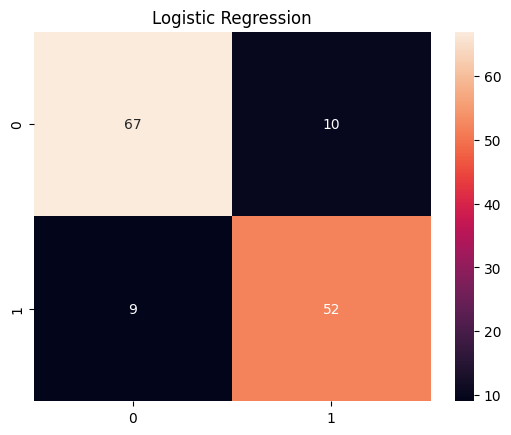

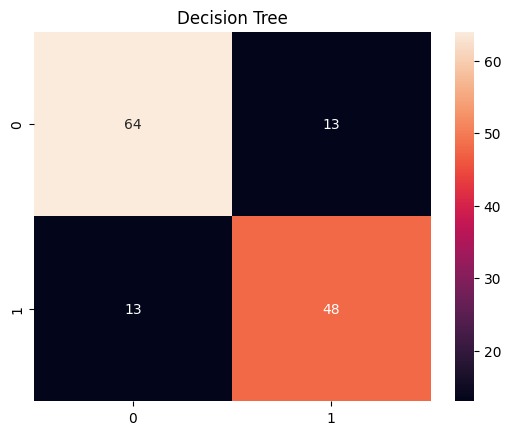

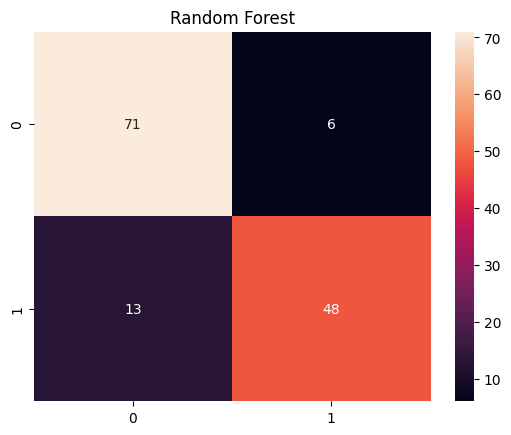

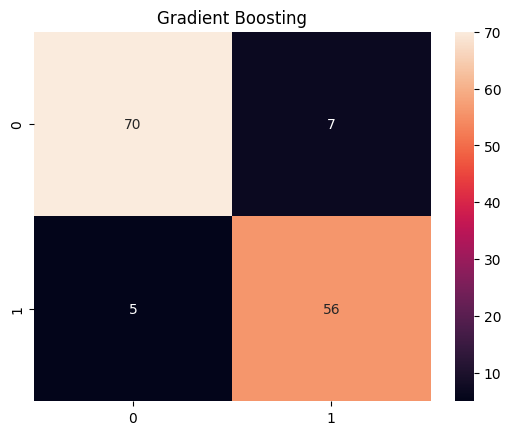

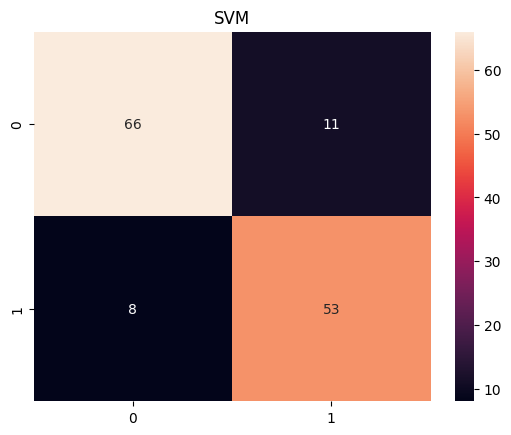

In [31]:
for name, model in trained_models.items():
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d")
    plt.title(name)
    plt.show()

## Check training versus test accuracy

Run a separate comparison that adds KNN and changes some estimator settings. Its Random Forest result belongs to a different fit from the main table.



Logistic Regression
Train Accuracy: 0.8768
Test Accuracy : 0.8623

Random Forest
Train Accuracy: 1.0000
Test Accuracy : 0.8986

Decision Tree
Train Accuracy: 0.9837
Test Accuracy : 0.8551

KNN
Train Accuracy: 0.8496
Test Accuracy : 0.7899

Gradient Boosting
Train Accuracy: 0.9728
Test Accuracy : 0.9130


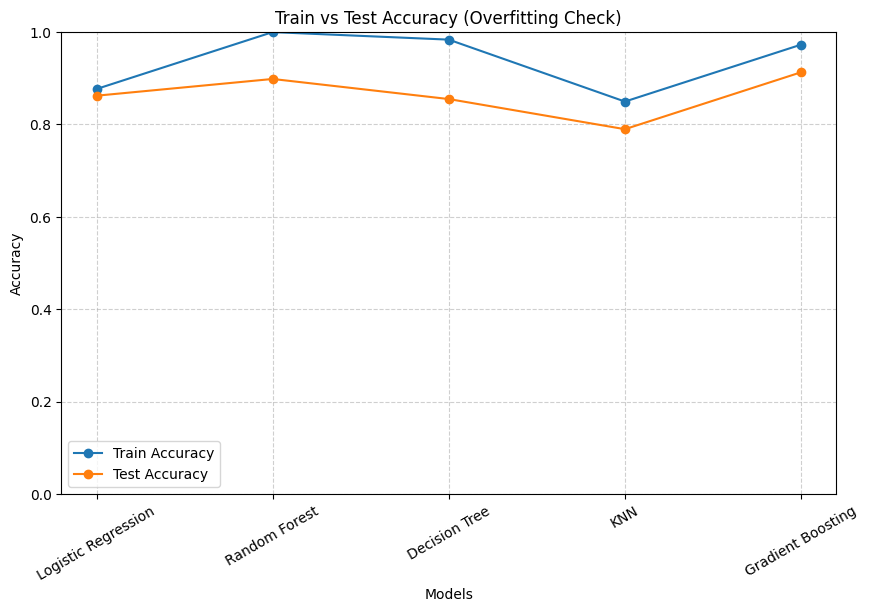

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


def plot_train_test_accuracy(X_train, X_test, y_train, y_test):

    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(random_state=42),
        "Decision Tree": DecisionTreeClassifier(max_depth=10),
        "KNN": KNeighborsClassifier(),
        "Gradient Boosting": GradientBoostingClassifier()
    }

    model_names = []
    train_scores = []
    test_scores = []

    for name, model in models.items():

        model.fit(X_train, y_train)


        train_pred = model.predict(X_train)
        train_acc = accuracy_score(y_train, train_pred)


        test_pred = model.predict(X_test)
        test_acc = accuracy_score(y_test, test_pred)

        model_names.append(name)
        train_scores.append(train_acc)
        test_scores.append(test_acc)

        print(f"\n{name}")
        print(f"Train Accuracy: {train_acc:.4f}")
        print(f"Test Accuracy : {test_acc:.4f}")


    plt.figure(figsize=(10,6))

    plt.plot(model_names, train_scores, marker='o', label="Train Accuracy")
    plt.plot(model_names, test_scores, marker='o', label="Test Accuracy")

    plt.title("Train vs Test Accuracy (Overfitting Check)")
    plt.xlabel("Models")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    plt.xticks(rotation=30)

    plt.show()
plot_train_test_accuracy(X_train_scaled, X_test_scaled, y_train, y_test)

## Generate a data profiling report

Create an exploratory HTML report from the raw UCI file. The generated HTML was not included with the supplied notebook.


In [25]:
import pandas as pd
from ydata_profiling import ProfileReport


url = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"
df = pd.read_csv(url, header=None)


profile = ProfileReport(
    df,
    title="Credit Dataset Profiling Report",
    explorative=True
)


profile.to_file("credit_report.html")

print("Report created: credit_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████| 16/16 [00:00<00:00, 300936.61it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Report created: credit_report.html
